# VaR y Expected Shortfall: cuatro métodos, su error de estimación y la subaditividad

**Perfil:** Riesgo financiero y riesgo de modelos  
**Datos:** sintéticos con semilla fija; se conoce el proceso generador, así que se puede comprobar si el método recupera la verdad.

## Pregunta que guía el notebook

¿Qué método de VaR/ES se equivoca menos con muestras de tamaño realista (250–5.000 días), y qué ocurre cuando **ningún** modelo contiene la verdad? ¿Por qué el regulador pasó de VaR a ES?

## Recorrido

1. Mundo con verdad **analítica** (t de Student) y mundo con verdad **fuera de la familia** (mezcla de normales).
2. **Cuatro métodos:** histórico, normal, t por máxima verosimilitud y teoría de valores extremos (GPD).
3. **Experimento:** sesgo y error cuadrático por tamaño de muestra, con 200 repeticiones.
4. **Incertidumbre:** intervalos de confianza para el VaR histórico y su cobertura real.
5. **Subaditividad:** un ejemplo donde el VaR penaliza la diversificación y el ES no.
6. Pruebas y límites.

Las conclusiones numéricas se **calculan y se imprimen desde los datos** (celdas «Lectura»), y las pruebas de la sección final hacen fallar el notebook si un hallazgo deja de cumplirse.

## 1. Configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 2026
plt.rcParams.update({"figure.figsize": (7.5, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format
from scipy import stats
from scipy.optimize import brentq

## 2. Dos mundos con verdad conocida

Se trabaja con **pérdidas** $L=-r$ (un valor alto es malo). Para un nivel $q$:
$$\mathrm{VaR}_q=\inf\{\ell:\ P(L\le \ell)\ge q\},\qquad \mathrm{ES}_q=\mathbb{E}[L\mid L\ge \mathrm{VaR}_q].$$

- **Mundo A (t de Student):** pérdidas $\sigma\sqrt{(\nu-2)/\nu}\;T_\nu$ con $\nu=4$ y $\sigma=1\%$ diario. VaR y ES tienen **forma cerrada**.
- **Mundo B (mezcla de normales):** 94 % de días tranquilos ($\sigma=0{,}8\%$) y 6 % de días turbulentos ($\sigma=2{,}6\%$). Tiene colas pesadas pero **no es una t**: ningún modelo de la lista lo contiene exactamente.

In [2]:
NU, SIGMA = 4, 0.01
ESC = SIGMA * np.sqrt((NU - 2) / NU)

def verdad_t(q, nu=NU, esc=ESC):
    tq = stats.t.ppf(q, nu)
    var = esc * tq
    es = esc * stats.t.pdf(tq, nu) / (1 - q) * (nu + tq ** 2) / (nu - 1)
    return var, es

PESOS, SIGMAS = np.array([0.94, 0.06]), np.array([0.008, 0.026])

def verdad_mezcla(q):
    cdf = lambda v: (PESOS * stats.norm.cdf(v / SIGMAS)).sum()
    var = brentq(lambda v: cdf(v) - q, 1e-6, 1.0)
    es = (PESOS * SIGMAS * stats.norm.pdf(var / SIGMAS)).sum() / (1 - q)
    return var, es

def muestra_t(n, rg): return -ESC * rg.standard_t(NU, n) * -1 * -1   # perdidas (simetrico)
def perdidas_t(n, rg): return ESC * rg.standard_t(NU, n)
def perdidas_mezcla(n, rg):
    k = rg.random(n) < PESOS[1]
    return np.where(k, rg.normal(0, SIGMAS[1], n), rg.normal(0, SIGMAS[0], n))

# verificacion de las formulas con una simulacion grande
rg0 = np.random.default_rng(1)
for nombre, gen, ver in (("t", perdidas_t, verdad_t), ("mezcla", perdidas_mezcla, verdad_mezcla)):
    L = gen(4_000_000, rg0)
    for q in (0.99, 0.975):
        v, e = ver(q)
        vs = np.quantile(L, q); es = L[L >= vs].mean()
        print(f"{nombre:7s} q={q}: VaR formula {v:.5f} vs sim {vs:.5f} | ES formula {e:.5f} vs sim {es:.5f}")
        assert abs(v / vs - 1) < 0.01 and abs(e / es - 1) < 0.015

t       q=0.99: VaR formula 0.02649 vs sim 0.02648 | ES formula 0.03692 vs sim 0.03687
t       q=0.975: VaR formula 0.01963 vs sim 0.01961 | ES formula 0.02824 vs sim 0.02821


mezcla  q=0.99: VaR formula 0.02608 vs sim 0.02611 | ES formula 0.03911 vs sim 0.03925
mezcla  q=0.975: VaR formula 0.01827 vs sim 0.01828 | ES formula 0.02830 vs sim 0.02837


## 3. Los cuatro métodos

1. **Histórico:** cuantil empírico y ES por la fórmula de Rockafellar-Uryasev, $\mathrm{ES}=\mathrm{VaR}+\mathbb{E}[(L-\mathrm{VaR})^+]/(1-q)$ (equivale al promedio de la cola en distribuciones continuas, pero es coherente también con masas puntuales).
2. **Normal (paramétrico):** media y desvío muestrales con fórmulas normales.
3. **t por máxima verosimilitud:** se ajusta $(\nu,\text{scale})$ con localización fija en 0 (habitual en retornos diarios) y se usan las fórmulas de la t.
4. **EVT (POT):** se ajusta una **distribución generalizada de Pareto** (GPD) a los excesos sobre el percentil 90, y se extrapola la cola:
$$\mathrm{VaR}_q=u+\frac{\beta}{\xi}\Big[\Big(\tfrac{n}{N_u}(1-q)\Big)^{-\xi}-1\Big],\qquad \mathrm{ES}_q=\frac{\mathrm{VaR}_q}{1-\xi}+\frac{\beta-\xi u}{1-\xi}.$$

In [3]:
# cada metodo se AJUSTA una sola vez por muestra y devuelve una funcion q -> (VaR, ES)
def es_ru(x, v, q):
    # Rockafellar-Uryasev: ES = VaR + E[(L - VaR)+] / (1-q). Coincide con la media de la cola en distribuciones continuas
    # y es COHERENTE (subaditivo) tambien con masas puntuales, a diferencia del promedio simple de la cola.
    return v + np.maximum(x - v, 0).mean() / (1 - q)

def hist(L):
    return lambda q: (lambda v: (v, es_ru(L, v, q)))(np.quantile(L, q))

def normal(L):
    m, s = L.mean(), L.std(ddof=1)
    return lambda q: (m + s * stats.norm.ppf(q), m + s * stats.norm.pdf(stats.norm.ppf(q)) / (1 - q))

def t_mle(L):
    nu, loc, esc = stats.t.fit(L, floc=0.0)      # localizacion fija en 0 (habitual en retornos diarios): ajusta solo (nu, escala) y es mucho mas rapido
    def f(q):
        if nu <= 1.05: return np.nan, np.nan
        tq = stats.t.ppf(q, nu)
        return loc + esc * tq, loc + esc * stats.t.pdf(tq, nu) / (1 - q) * (nu + tq ** 2) / (nu - 1)
    return f

def evt(L, umbral_q=0.90):
    u = np.quantile(L, umbral_q); exc = L[L > u] - u
    if len(exc) < 20: return lambda q: (np.nan, np.nan)
    xi, _, beta = stats.genpareto.fit(exc, floc=0)
    n, nu_ = len(L), len(exc)
    def f(q):
        if xi >= 0.95 or xi <= -0.5: return np.nan, np.nan
        var = u + beta / xi * (((n / nu_) * (1 - q)) ** (-xi) - 1) if abs(xi) > 1e-8 else u - beta * np.log((n / nu_) * (1 - q))
        return var, var / (1 - xi) + (beta - xi * u) / (1 - xi)
    return f

METODOS = {"historico": hist, "normal": normal, "t (MLE)": t_mle, "EVT (GPD)": evt}
rg = np.random.default_rng(3)
L_ej = perdidas_t(2500, rg)
v_t, e_t = verdad_t(0.99)
pd.DataFrame({m: dict(zip(["VaR99", "ES99"], f(L_ej)(0.99))) for m, f in METODOS.items()}).assign(verdad=[v_t, e_t]).T.round(5)

,VaR99,ES99
historico,0.0270,0.0358
normal,0.0232,0.0266
t (MLE),0.0273,0.0379
EVT (GPD),0.0267,0.0367
verdad,0.0265,0.0369


## 4. Experimento: sesgo y error por tamaño de muestra

Para cada tamaño $n$ se generan **150 muestras independientes** y se calculan los cuatro métodos. Métricas: **sesgo relativo** (media del cociente estimado/verdadero menos 1) y **RMSE relativo**.

In [4]:
def experimento(gen, ver, tamanos, q_var=0.99, q_es=0.975, R=150, seed=0):
    rg = np.random.default_rng(seed)
    v_ver, _ = ver(q_var); _, e_ver = ver(q_es)
    filas = []
    for n in tamanos:
        est = {m: {"var": [], "es": []} for m in METODOS}
        for _ in range(R):
            L = gen(n, rg)
            for m, f in METODOS.items():
                modelo = f(L)
                est[m]["var"].append(modelo(q_var)[0]); est[m]["es"].append(modelo(q_es)[1])
        for m in METODOS:
            for tipo, ver_ in (("var", v_ver), ("es", e_ver)):
                x = np.array(est[m][tipo], float) / ver_
                ok = ~np.isnan(x)
                filas.append({"n": n, "metodo": m, "medida": "VaR 99%" if tipo == "var" else "ES 97.5%", "sesgo_%": (np.nanmean(x) - 1) * 100,
                              "RMSE_%": np.sqrt(np.nanmean((x - 1) ** 2)) * 100, "fallos": int((~ok).sum())})
    return pd.DataFrame(filas)

TAM = [250, 500, 1000, 2500, 5000]
res_t = experimento(perdidas_t, verdad_t, TAM, seed=11)
res_m = experimento(perdidas_mezcla, verdad_mezcla, TAM, seed=12)
print("Mundo A (t de Student), n=500 y n=2500:")
res_t[res_t["n"].isin([500, 2500])].pivot_table(index=["medida", "metodo"], columns="n", values=["sesgo_%", "RMSE_%"]).round(1)

Mundo A (t de Student), n=500 y n=2500:


RMSE_%          sesgo_%         
n                     500     2500     500      2500
medida   metodo                                     
ES 97.5% EVT (GPD) 13.7000  6.0000  -1.6000   0.1000
         historico 13.3000  6.1000  -2.0000   0.1000
         normal    19.2000 17.3000 -18.1000 -17.0000
         t (MLE)    9.8000  4.0000  -0.8000   0.3000
VaR 99%  EVT (GPD) 10.6000  4.9000  -0.5000   1.1000
         historico 12.9000  5.7000  -4.2000   0.2000
         normal    14.8000 12.4000 -13.2000 -12.0000
         t (MLE)    8.2000  3.3000  -0.9000   0.3000

In [5]:
print("Mundo B (mezcla de normales), n=500 y n=2500:")
res_m[res_m["n"].isin([500, 2500])].pivot_table(index=["medida", "metodo"], columns="n", values=["sesgo_%", "RMSE_%"]).round(1)

Mundo B (mezcla de normales), n=500 y n=2500:


RMSE_%          sesgo_%         
n                     500     2500     500      2500
medida   metodo                                     
ES 97.5% EVT (GPD) 17.8000  8.1000   0.4000   1.7000
         historico 15.3000  7.1000  -1.5000   0.6000
         normal    17.6000 17.3000 -16.8000 -17.1000
         t (MLE)    9.8000  5.7000  -3.5000  -4.4000
VaR 99%  EVT (GPD) 12.4000  5.7000  -0.9000   0.1000
         historico 18.9000 10.2000  -2.0000   0.8000
         normal    11.7000 10.8000 -10.1000 -10.5000
         t (MLE)    8.0000  3.5000  -0.6000  -1.3000

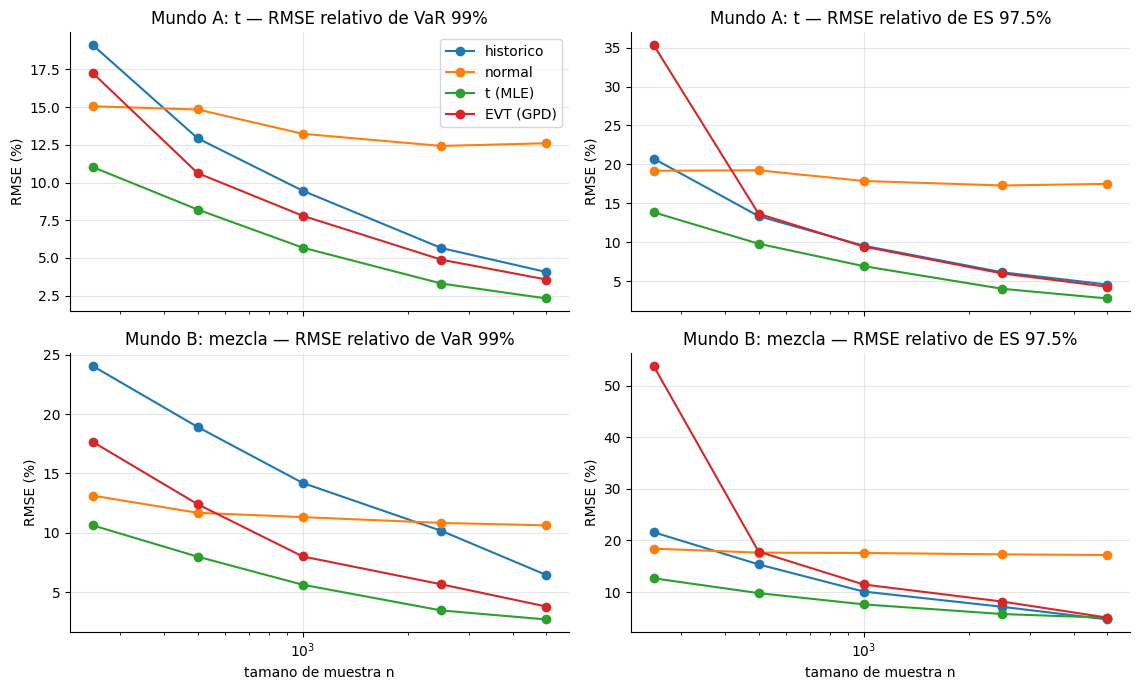

In [6]:
fig, ax = plt.subplots(2, 2, figsize=(11.5, 7), sharex=True)
for i, (res, nombre) in enumerate(((res_t, "Mundo A: t"), (res_m, "Mundo B: mezcla"))):
    for j, medida in enumerate(("VaR 99%", "ES 97.5%")):
        for m in METODOS:
            d = res[(res["medida"] == medida) & (res["metodo"] == m)]
            ax[i, j].plot(d["n"], d["RMSE_%"], "o-", label=m)
        ax[i, j].set_xscale("log"); ax[i, j].set_title(f"{nombre} — RMSE relativo de {medida}"); ax[i, j].set_ylabel("RMSE (%)")
ax[1, 0].set_xlabel("tamano de muestra n"); ax[1, 1].set_xlabel("tamano de muestra n"); ax[0, 0].legend(); plt.tight_layout(); plt.show()

In [7]:
def mejor(res, medida, n):
    d = res[(res["medida"] == medida) & (res["n"] == n)].set_index("metodo")["RMSE_%"]
    return d.idxmin(), d.min()

print("Lectura:")
for nombre, res in (("Mundo A (t)", res_t), ("Mundo B (mezcla)", res_m)):
    for medida in ("VaR 99%", "ES 97.5%"):
        for n in (250, 2500):
            m, r = mejor(res, medida, n)
            print(f"  {nombre:18s} {medida:9s} n={n:<5d}: menor RMSE = {m} ({r:.1f}%)")
sn_t = res_t[(res_t["medida"] == "ES 97.5%") & (res_t["metodo"] == "normal")]["sesgo_%"].mean()
sn_m = res_m[(res_m["medida"] == "ES 97.5%") & (res_m["metodo"] == "normal")]["sesgo_%"].mean()
print(f"  El metodo normal subestima el ES 97.5% en {abs(sn_t):.0f}% (mundo A) y {abs(sn_m):.0f}% (mundo B), casi independientemente de n: es un sesgo de MODELO, no de muestra.")
tm = res_m[(res_m["medida"] == "ES 97.5%") & (res_m["metodo"] == "t (MLE)")].set_index("n")
hm = res_m[(res_m["medida"] == "ES 97.5%") & (res_m["metodo"] == "historico")].set_index("n")
print(f"  Mundo B (la t esta MAL especificada): su sesgo en ES 97.5% es {tm['sesgo_%'].mean():+.1f}% y no desaparece con n; el historico tiene sesgo ~0 pero mas varianza.")
cruce = [n for n in tm.index if hm.loc[n, "RMSE_%"] < tm.loc[n, "RMSE_%"]]
print(f"  En ES 97.5% (mundo B) el historico supera a la t en RMSE para n = {cruce if cruce else 'ningun tamano probado'}: el sesgo de modelo termina pesando mas que la varianza cuando n es grande.")

Lectura:
  Mundo A (t)        VaR 99%   n=250  : menor RMSE = t (MLE) (11.0%)
  Mundo A (t)        VaR 99%   n=2500 : menor RMSE = t (MLE) (3.3%)
  Mundo A (t)        ES 97.5%  n=250  : menor RMSE = t (MLE) (13.8%)
  Mundo A (t)        ES 97.5%  n=2500 : menor RMSE = t (MLE) (4.0%)
  Mundo B (mezcla)   VaR 99%   n=250  : menor RMSE = t (MLE) (10.6%)
  Mundo B (mezcla)   VaR 99%   n=2500 : menor RMSE = t (MLE) (3.5%)
  Mundo B (mezcla)   ES 97.5%  n=250  : menor RMSE = t (MLE) (12.7%)
  Mundo B (mezcla)   ES 97.5%  n=2500 : menor RMSE = t (MLE) (5.7%)
  El metodo normal subestima el ES 97.5% en 17% (mundo A) y 17% (mundo B), casi independientemente de n: es un sesgo de MODELO, no de muestra.
  Mundo B (la t esta MAL especificada): su sesgo en ES 97.5% es -4.0% y no desaparece con n; el historico tiene sesgo ~0 pero mas varianza.
  En ES 97.5% (mundo B) el historico supera a la t en RMSE para n = [5000]: el sesgo de modelo termina pesando mas que la varianza cuando n es grande.


**Qué muestra.** Hay dos fuentes de error distintas. El **error de muestreo** cae con $n$ (por eso el RMSE baja) y es grande para el histórico con muestras cortas, porque la cola se estima con muy pocos puntos. El **error de modelo** (sesgo) **no desaparece** con más datos: el método normal subestima la cola aunque $n$ sea enorme. Un método paramétrico bien especificado (la t en el mundo A) es el más preciso. En el mundo B la t está **mal especificada** pero sigue siendo muy competitiva en RMSE para muestras cortas y medianas; lo que la separa del histórico es un **sesgo persistente** en el ES que el histórico no tiene, y que pesa más cuando $n$ crece (ver la lectura de arriba).

## 5. Incertidumbre del VaR histórico

Un VaR del 99 % con $n=500$ se apoya en unos 5 puntos. Se compara el **intervalo de confianza** del cuantil construido por (i) *bootstrap* percentil y (ii) estadísticos de orden (binomial), y se mide su **cobertura real** en el mundo A, donde se conoce el valor verdadero.

In [8]:
def ic_bootstrap(L, q, B=400, rg=None):
    n = len(L); b = np.array([np.quantile(L[rg.integers(0, n, n)], q) for _ in range(B)])
    return np.percentile(b, [2.5, 97.5])

def ic_orden(L, q, alfa=0.05):
    n = len(L); s = np.sort(L)
    lo = max(int(stats.binom.ppf(alfa / 2, n, q)), 0); hi = min(int(stats.binom.ppf(1 - alfa / 2, n, q)) + 1, n - 1)
    return s[lo], s[hi]

v_ver, _ = verdad_t(0.99)
rg = np.random.default_rng(21)
filas = []
for n in (250, 500, 1000, 2500):
    cb = co = 0; ab = ao = 0; R = 300
    for _ in range(R):
        L = perdidas_t(n, rg)
        lo, hi = ic_bootstrap(L, 0.99, B=200, rg=rg); cb += lo <= v_ver <= hi; ab += hi - lo
        lo, hi = ic_orden(L, 0.99); co += lo <= v_ver <= hi; ao += hi - lo
    filas.append({"n": n, "cobertura_bootstrap": cb / R, "cobertura_orden": co / R, "ancho_bootstrap": ab / R, "ancho_orden": ao / R})
ic = pd.DataFrame(filas).set_index("n")
ic.round(3)

,cobertura_bootstrap,cobertura_orden,ancho_bootstrap,ancho_orden
n,,,,
250,0.8870,0.8770,0.0200,0.0230
500,0.8800,0.9530,0.0140,0.0310
1000,0.9300,0.9730,0.0100,0.0170
2500,0.9630,0.9530,0.0060,0.0070


In [9]:
print("Lectura: cobertura nominal 95%.")
for n_ in ic.index:
    print(f"  n={n_:<5d}: cobertura bootstrap {ic.loc[n_, 'cobertura_bootstrap']:.0%} | intervalo de orden {ic.loc[n_, 'cobertura_orden']:.0%}")
print(f"  Con muestras cortas ambos quedan bajo el 95% nominal ({ic.loc[250, 'cobertura_bootstrap']:.0%} y {ic.loc[250, 'cobertura_orden']:.0%} con n=250): con 2-3 puntos de cola, el intervalo es optimista. (Error estandar de cada cobertura ~1.3 pts con 300 repeticiones.)")
print(f"  El ancho del intervalo (en pts de perdida) baja de {ic.loc[250, 'ancho_orden']:.4f} a {ic.loc[2500, 'ancho_orden']:.4f} al pasar de n=250 a n=2500.")
if not ic["ancho_orden"].is_monotonic_decreasing:
    print("  El ancho del intervalo de orden NO baja de forma monotona (salta con n): los indices del estadistico de orden son enteros y el intervalo cambia a saltos; el bootstrap si baja de forma monotona.")

Lectura: cobertura nominal 95%.
  n=250  : cobertura bootstrap 89% | intervalo de orden 88%
  n=500  : cobertura bootstrap 88% | intervalo de orden 95%
  n=1000 : cobertura bootstrap 93% | intervalo de orden 97%
  n=2500 : cobertura bootstrap 96% | intervalo de orden 95%
  Con muestras cortas ambos quedan bajo el 95% nominal (89% y 88% con n=250): con 2-3 puntos de cola, el intervalo es optimista. (Error estandar de cada cobertura ~1.3 pts con 300 repeticiones.)
  El ancho del intervalo (en pts de perdida) baja de 0.0231 a 0.0073 al pasar de n=250 a n=2500.
  El ancho del intervalo de orden NO baja de forma monotona (salta con n): los indices del estadistico de orden son enteros y el intervalo cambia a saltos; el bootstrap si baja de forma monotona.


## 6. Subaditividad: por qué el VaR no es una medida coherente

Una medida de riesgo $\rho$ es **subaditiva** si $\rho(A+B)\le\rho(A)+\rho(B)$ (diversificar no puede aumentar el riesgo). El ES lo es siempre; el VaR **no**. Ejemplo clásico: dos bonos independientes, cada uno con probabilidad de default de 4 % y pérdida de 100 si cae.

In [10]:
rg = np.random.default_rng(5)
S = 2_000_000
a = (rg.random(S) < 0.04) * 100.0; b = (rg.random(S) < 0.04) * 100.0
def var_es(x, q):
    v = np.quantile(x, q, method="higher"); return v, es_ru(x, v, q)
q = 0.95
va, ea = var_es(a, q); vb, eb = var_es(b, q); vab, eab = var_es(a + b, q)
print(f"Nivel {q}: VaR(A)={va:.0f}, VaR(B)={vb:.0f}, VaR(A+B)={vab:.0f}  -> suma individual {va + vb:.0f}: VaR {'NO es subaditivo (diversificar aumenta el riesgo)' if vab > va + vb else 'subaditivo'}")
print(f"           ES(A)={ea:.1f}, ES(B)={eb:.1f}, ES(A+B)={eab:.1f}  -> suma individual {ea + eb:.1f}: ES {'subaditivo' if eab <= ea + eb + 1e-9 else 'NO subaditivo'}")
print(f"Probabilidad de al menos un default: {1 - 0.96 ** 2:.4f} > 1-q = {1 - q}: por eso el VaR conjunto salta a 100.")
print(f"Valores exactos: ES(A)=ES(B)=0.04*100/0.05 = 80, ES(A+B) = 100 + (0.0016*100)/0.05 = 103.2 <= 160.")
print("Nota de metodo: el ES se calcula con Rockafellar-Uryasev. El promedio simple de la cola (CTE) NO es subaditivo con masas puntuales; una primera version de este notebook lo uso y mostro una violacion espuria.")

Nivel 0.95: VaR(A)=0, VaR(B)=0, VaR(A+B)=100  -> suma individual 0: VaR NO es subaditivo (diversificar aumenta el riesgo)
           ES(A)=80.1, ES(B)=79.5, ES(A+B)=103.2  -> suma individual 159.6: ES subaditivo
Probabilidad de al menos un default: 0.0784 > 1-q = 0.050000000000000044: por eso el VaR conjunto salta a 100.
Valores exactos: ES(A)=ES(B)=0.04*100/0.05 = 80, ES(A+B) = 100 + (0.0016*100)/0.05 = 103.2 <= 160.
Nota de metodo: el ES se calcula con Rockafellar-Uryasev. El promedio simple de la cola (CTE) NO es subaditivo con masas puntuales; una primera version de este notebook lo uso y mostro una violacion espuria.


In [11]:
# prueba aleatoria: el ES es subaditivo en carteras de perdidas dependientes aleatorias; el VaR a veces no
viola_var = viola_es = 0; ensayos = 400
rg = np.random.default_rng(8)
for _ in range(ensayos):
    p1, p2 = rg.uniform(0.01, 0.12, 2); l1, l2 = rg.uniform(20, 200, 2)
    x = (rg.random(20_000) < p1) * l1; y = (rg.random(20_000) < p2) * l2
    v1, e1 = var_es(x, 0.95); v2, e2 = var_es(y, 0.95); v12, e12 = var_es(x + y, 0.95)
    viola_var += v12 > v1 + v2 + 1e-9; viola_es += e12 > e1 + e2 + 1e-6
print(f"En {ensayos} pares de creditos aleatorios independientes (nivel 95%): el VaR viola la subaditividad en {viola_var} casos, el ES en {viola_es}.")

En 400 pares de creditos aleatorios independientes (nivel 95%): el VaR viola la subaditividad en 41 casos, el ES en 0.


## 7. Pruebas automáticas

In [12]:
# 7.1 las formulas analiticas coinciden con la simulacion (verificadas en la seccion 2) y ES >= VaR
for ver in (verdad_t, verdad_mezcla):
    for q_ in (0.9, 0.95, 0.975, 0.99):
        v_, e_ = ver(q_); assert e_ > v_ > 0
# 7.2 monotonia en el nivel de confianza
assert verdad_t(0.99)[0] > verdad_t(0.95)[0] and verdad_t(0.99)[1] > verdad_t(0.95)[1]
# 7.3 cada metodo devuelve ES >= VaR en una muestra grande
L_g = perdidas_t(200_000, np.random.default_rng(2))
for m, f in METODOS.items():
    v_, e_ = f(L_g)(0.99); assert e_ >= v_, m
# 7.4 el metodo normal subestima sistematicamente el ES en ambos mundos, sin importar n (error de modelo)
nm_t = res_t[(res_t["medida"] == "ES 97.5%") & (res_t["metodo"] == "normal")]
nm_m = res_m[(res_m["medida"] == "ES 97.5%") & (res_m["metodo"] == "normal")]
assert (nm_t["sesgo_%"] < -5).all() and (nm_m["sesgo_%"] < -3).all()
assert abs(nm_t["sesgo_%"].iloc[-1] - nm_t["sesgo_%"].iloc[0]) < 15, "el sesgo de modelo no debe desaparecer con n"
# 7.5 el RMSE del historico y de la t bien especificada baja con n
for res in (res_t,):
    for m in ("historico", "t (MLE)"):
        d = res[(res["medida"] == "VaR 99%") & (res["metodo"] == m)].set_index("n")["RMSE_%"]
        assert d.loc[5000] < d.loc[250]
# 7.6 con el modelo bien especificado (t en el mundo A), la t es la mas precisa a n grande
d = res_t[(res_t["medida"] == "VaR 99%") & (res_t["n"] == 5000)].set_index("metodo")["RMSE_%"]
assert d["t (MLE)"] <= d.drop("t (MLE)").min() * 1.15
# 7.7 los intervalos: cobertura razonable con n grande y ancho decreciente
assert ic.loc[2500, "cobertura_orden"] > 0.88 and ic.loc[2500, "cobertura_bootstrap"] > 0.85
assert ic["ancho_bootstrap"].is_monotonic_decreasing and ic.loc[2500, "ancho_orden"] < ic.loc[250, "ancho_orden"]   # el de orden salta por discretizacion de los indices
# 7.8 subaditividad: el VaR la viola en el ejemplo de dos bonos; el ES (Rockafellar-Uryasev) NUNCA la viola, ni siquiera por ruido
assert vab > va + vb
assert abs(ea - 80) < 2 and abs(eab - 103.2) < 2 and eab <= ea + eb + 1e-9
assert viola_es == 0 and viola_var > 0
# 7.9 el ES de RU coincide con el promedio de la cola en una distribucion continua grande
Lc = perdidas_t(2_000_000, np.random.default_rng(4)); vc = np.quantile(Lc, 0.975)
assert abs(es_ru(Lc, vc, 0.975) / Lc[Lc >= vc].mean() - 1) < 1e-3
# 7.10 en el mundo B la t mal especificada conserva un sesgo de ES que no desaparece con n
tm_ = res_m[(res_m["medida"] == "ES 97.5%") & (res_m["metodo"] == "t (MLE)")]["sesgo_%"]
assert (tm_.iloc[-3:] < -2).all() and abs(tm_.iloc[-1] - tm_.iloc[-3]) < 3
print("Todas las pruebas pasaron.")

Todas las pruebas pasaron.


## Conclusiones y límites

| Paso | Qué se encontró | Decisión |
|---|---|---|
| Dos fuentes de error | El error de muestreo baja con n; el sesgo de modelo (p. ej., el método normal) no | Distinguir ambos antes de culpar a los datos |
| Histórico | Con muestras cortas estima la cola con muy pocos puntos y su error es grande | Evitarlo para niveles extremos con pocas observaciones |
| Modelo bien especificado | La t por MLE es la más precisa cuando la verdad está en su familia | Su ventaja depende de la especificación |
| Mundo fuera de la familia | La t mal especificada sigue siendo competitiva en RMSE con n corto o mediano, pero conserva un sesgo de ≈−4 % en el ES que el histórico no tiene | Comparar métodos en más de un escenario de verdad y vigilar el sesgo residual |
| Incertidumbre | Los intervalos de confianza del VaR son anchos; se mide su cobertura real | Reportar el VaR con su intervalo |
| Coherencia | El VaR viola la subaditividad en ejemplos de pocos eventos; el ES (Rockafellar-Uryasev) no. El promedio simple de la cola sí la viola con masas puntuales | Preferir ES y calcularlo con una fórmula coherente |

**Límites que no deben ocultarse**

- Los datos son i.i.d.: no hay agrupamiento de volatilidad, que es el problema central de los datos reales (ver los notebooks de backtesting y GARCH).
- Los dos mundos de verdad se eligieron por tener forma cerrada; los mercados reales no coinciden con ninguno.
- La GPD usa un umbral fijo en el percentil 90; con otros umbrales el sesgo y la varianza cambian.
- 150 repeticiones por celda dan ruido de simulación de unos pocos puntos porcentuales en las tablas.
- Datos sintéticos: ningún valor numérico es extrapolable a una cartera real.